# Dataset Description
## Departments of the contracting entity by presidnet term

**Source**: [Agencia Nacional De Contratos Publicos](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Contratos-Electr-nicos/jbjy-vk9h/about_data)

# Code
## Imports

In [8]:
from matplotlib import use
import pandas as pd
import matplotlib.pyplot as plt

## Load data

In [9]:
path = "./data/SECOP_II_-_Contratos_Electrónicos_20261107.csv"

df = pd.read_csv(
    path, encoding="utf-8", usecols=[1, 6], header=0,
    names=["departamento", "fecha"]
)

## Clean Data

In [10]:
df = df[["fecha", "departamento"]]

df["fecha"] = df["fecha"].str.split(" ").str[0]

df["fecha"] = pd.to_datetime(df["fecha"])

df_f = df[df["fecha"] < "2026-08-07"]

In [11]:
years = [2014, 2018, 2022]
names = ["Santos", "Duque", "Petro"]

presidents = []
for i in range(len(years)):
    tmp = df_f[
        (df_f["fecha"] > f"{years[i]}-08-07") &
        (df_f["fecha"] < f"{years[i] + 4}-08-07")
    ].drop(columns=["fecha"])

    tmp["contratos"] = 1

    tmp_f = tmp.groupby("departamento").sum().squeeze().sort_values(ascending=False)

    tmp_f.name = names[i]

    presidents.append(tmp_f)

## Plot

In [12]:
import json
import unicodedata
from pathlib import Path
import matplotlib.cm as cm
from matplotlib.colors import PowerNorm
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from highlight_text import fig_text

BASE_DIR = Path.cwd().parent.parent
logo = plt.imread(BASE_DIR / "logo/logo.png")
with open("./data/colombia_departments.geojson", encoding="utf-8") as f:
    geo = json.load(f)

In [17]:
background = "#F4F1EA"
cmap = cm.Reds
missing_color = "#D3D3D3"
sanandres_box = {"lon": (-79.0, -75.9), "lat": (10.9, 13.3)}


def normalize(name: str) -> str:
    ascii_name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode()
    return ascii_name.upper().strip()


# Names that differ between SECOP and the geojson.
name_to_code = {normalize(f["properties"]["NOMBRE_DPT"]): f["properties"]["DPTO"]
                for f in geo["features"]}
name_to_code["DISTRITO CAPITAL DE BOGOTA"] = "11"
name_to_code["SAN ANDRES, PROVIDENCIA Y SANTA CATALINA"] = "88"

# Share of each term's contracts, so terms of different length are comparable.
# "No Definido" has no department and is left out of the maps.
shares = {}
for s in presidents:
    s = s[s.index != "No Definido"]
    s = s.rename(index=lambda n: name_to_code[normalize(n)])
    shares[s.name] = s / s.sum() * 100
totals = {s.name: s.sum() for s in presidents}

# Shared scale so every term's map is directly comparable; sqrt because
# Bogotá would otherwise wash out every other department.
norm = PowerNorm(gamma=0.5, vmin=0, vmax=max(s.max() for s in shares.values()))


def exterior_rings(geometry: dict) -> list:
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"][0]]
    return [poly[0] for poly in geometry["coordinates"]]


def bbox_area(ring: list) -> float:
    xs = [x for x, _ in ring]
    ys = [y for _, y in ring]
    return (max(xs) - min(xs)) * (max(ys) - min(ys))


def fit_box(rings: list, box: dict) -> list:
    """Uniform scale + center rings into a target lon/lat box (preserve aspect)."""
    xs = [x for r in rings for x, _ in r]
    ys = [y for r in rings for _, y in r]
    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
    bx0, bx1 = box["lon"]
    by0, by1 = box["lat"]
    scale = min((bx1 - bx0) / (x1 - x0), (by1 - by0) / (y1 - y0))
    ox = bx0 + ((bx1 - bx0) - (x1 - x0) * scale) / 2
    oy = by0 + ((by1 - by0) - (y1 - y0) * scale) / 2
    return [[(ox + (x - x0) * scale, oy + (y - y0) * scale) for x, y in r]
            for r in rings]


def plot_term_map(name: str, period: str):
    rates = shares[name]
    fig, ax = plt.subplots(figsize=(10.8, 13.5), dpi=500)
    fig.patch.set_facecolor(background)
    ax.patch.set_facecolor(background)

    patches, colors = [], []
    for feat in geo["features"]:
        code = feat["properties"]["DPTO"]
        val = rates.get(code)
        color = missing_color if pd.isna(val) else cmap(norm(val))
        rings = exterior_rings(feat["geometry"])
        if code == "88":
            rings = fit_box([max(rings, key=bbox_area)], sanandres_box)
        for ring in rings:
            patches.append(Polygon(ring, closed=True))
            colors.append(color)

    ax.add_collection(PatchCollection(
        patches, facecolor=colors, edgecolor="white", linewidth=0.4))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_position([0.03, 0.10, 0.78, 0.74])

    ax.text(-77.45, 10.6, "San Andrés", fontsize=8, color="gray",
            ha="center", va="top")

    fig_text(
        x=0.06, y=0.95,
        s=f"Executive contracts by department · <{name}>",
        highlight_textprops=[{"color": cmap(0.85), "weight": "bold"}],
        fontsize=18,
    )
    fig_text(
        x=0.06, y=0.92,
        s=f"approved contracts · department of the contracting entity · {period}",
        fontsize=11, color="gray",
    )

    fig_text(
        x=0.60, y=0.88,
        s=f"<{totals[name]:,.0f}>\ncontracts signed",
        highlight_textprops=[{"color": cmap(0.85), "weight": "bold", "fontsize": 32}],
        fontsize=11, color="gray",
    )

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    cax = fig.add_axes([0.87, 0.3, 0.025, 0.4])
    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label("% of the term's contracts (sqrt scale)", fontsize=9, color="gray")
    cbar.ax.tick_params(labelsize=9, colors="gray")
    cbar.outline.set_visible(False)

    fig.text(
        0.06, 0.04,
        "Source: Agencia Nacional de Contratación Pública (SECOP II).",
        fontsize=9, color="gray")
    if name == "Santos":
        fig.text(
            0.06, 0.02,
            "*Only 1 contract in 2015: the dataset starts in Nov 2015.",
            fontsize=9, color="gray")

    imagebox = OffsetImage(logo, zoom=0.4)
    ab = AnnotationBbox(imagebox, xy=(0.79, 0.045), xycoords="figure fraction",
                        frameon=False, pad=0)
    fig.add_artist(ab)

    plt.show()
    plt.close(fig)

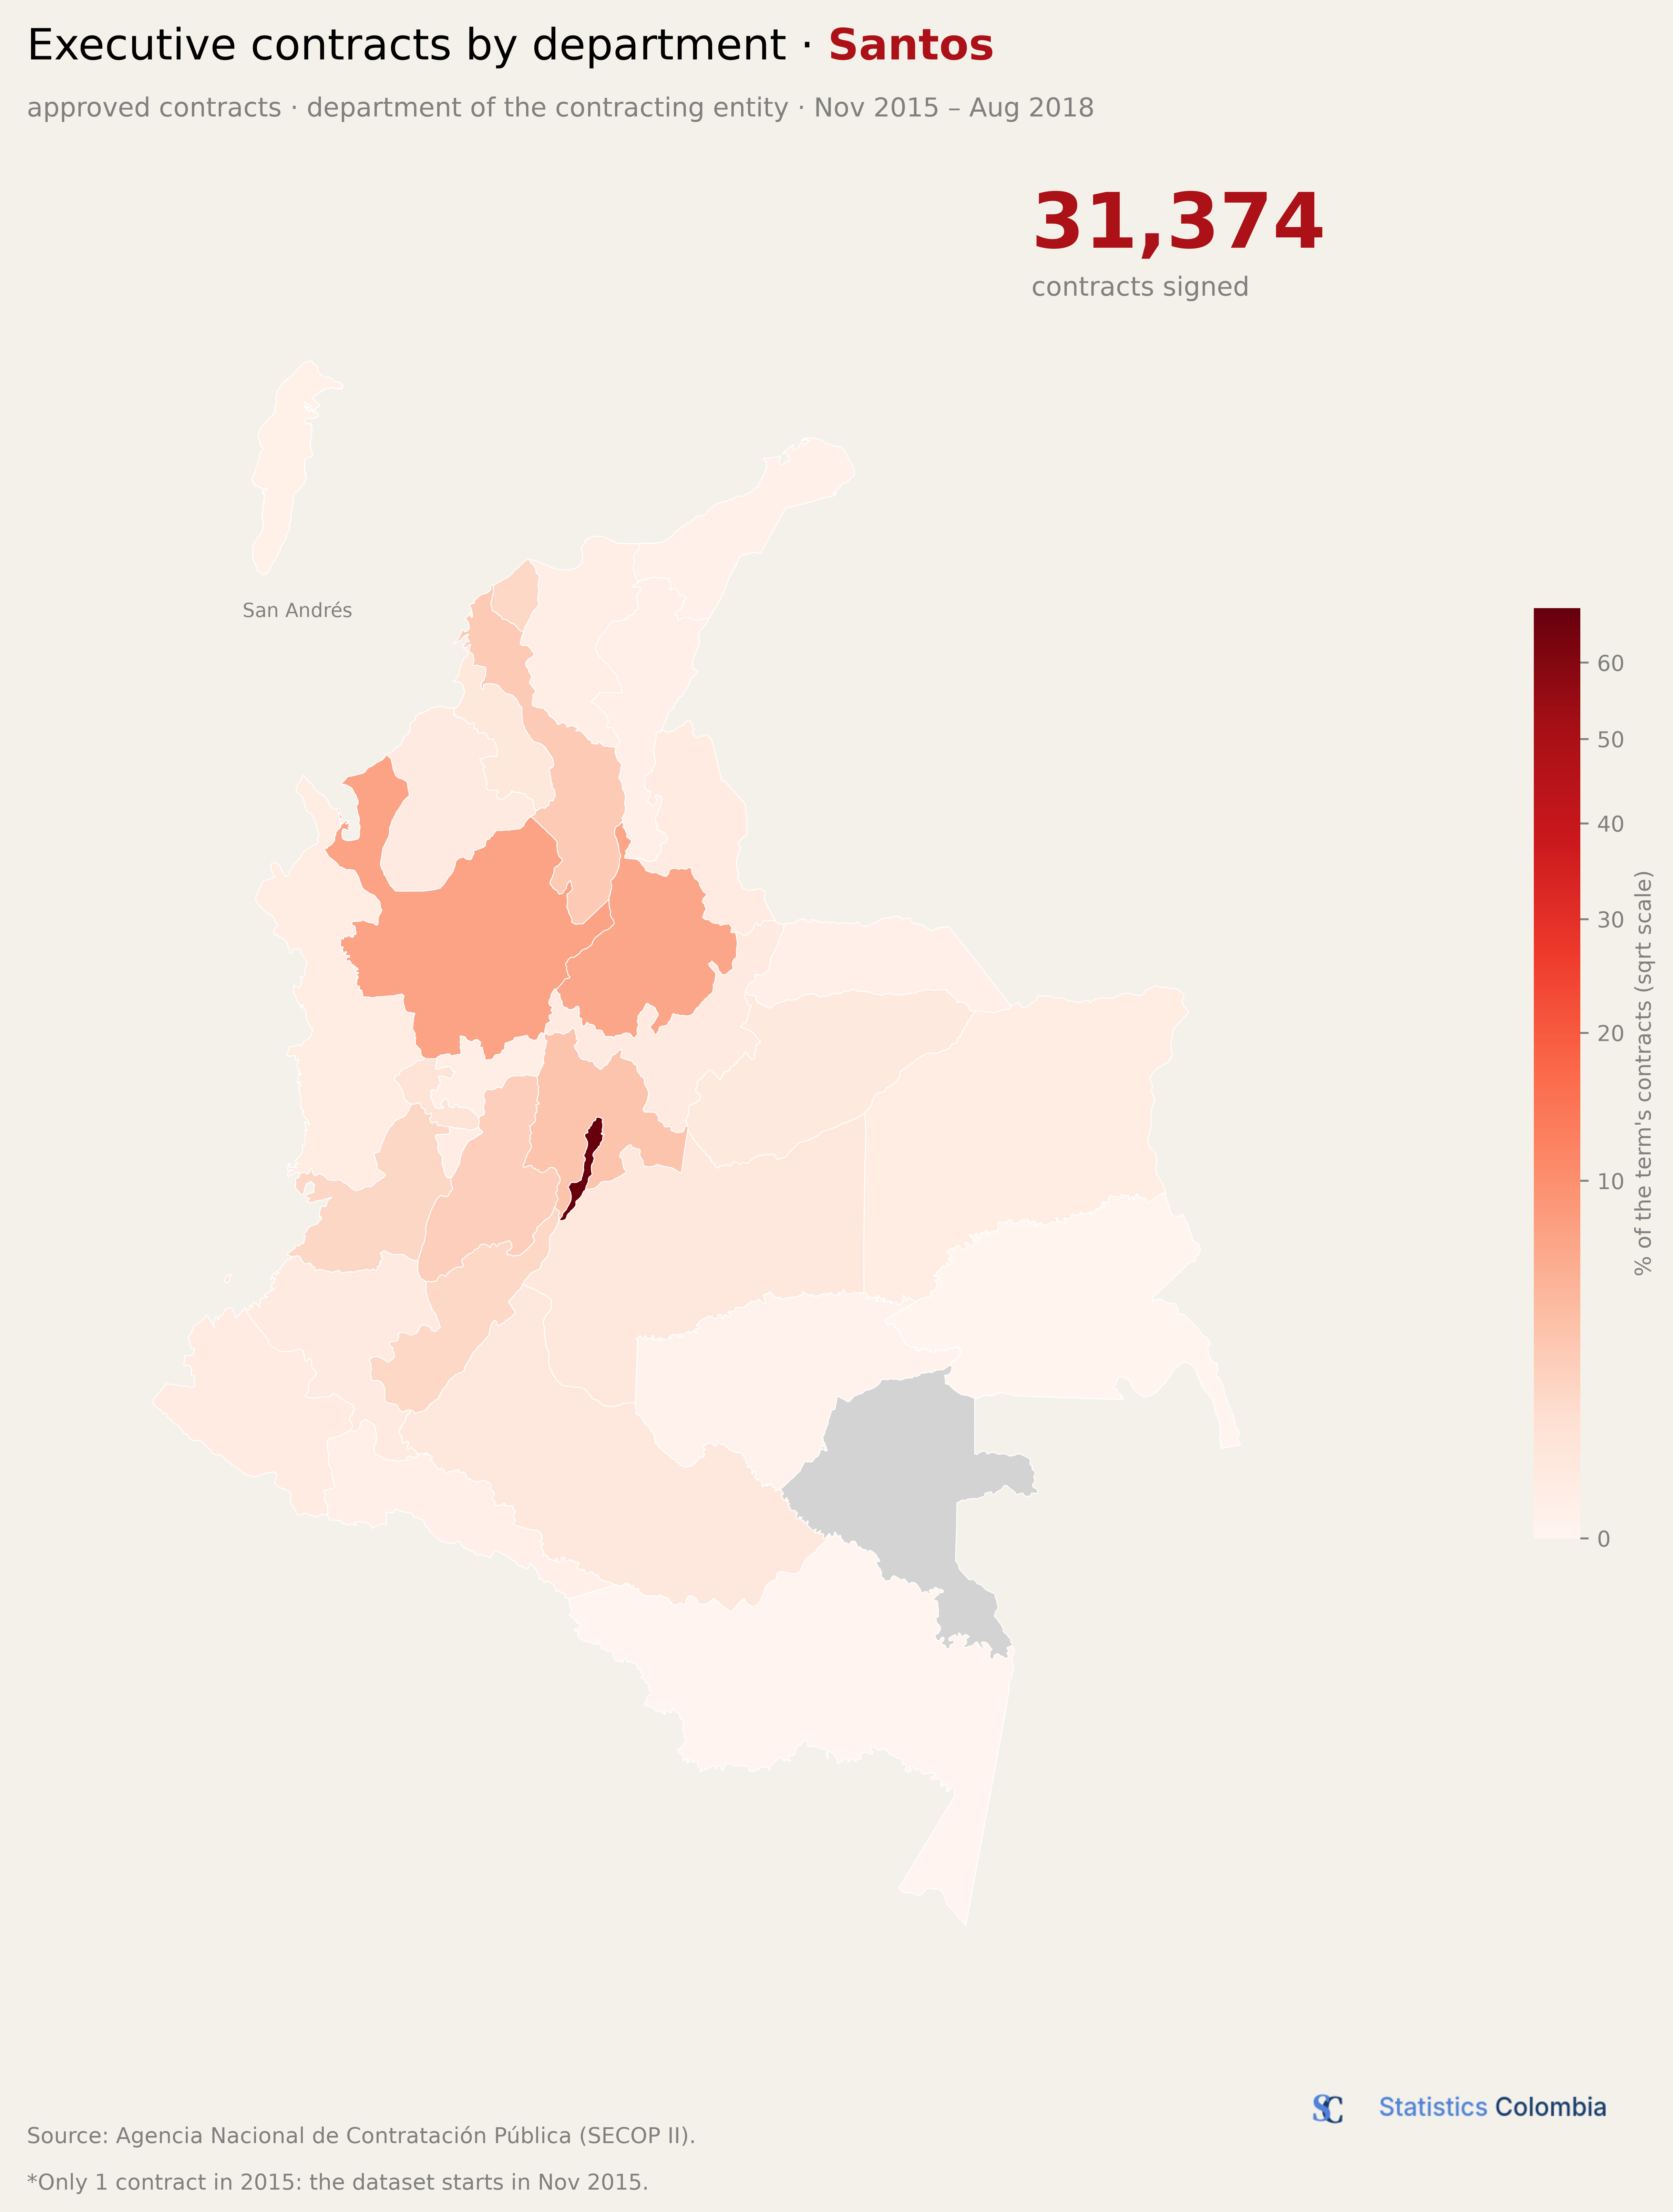

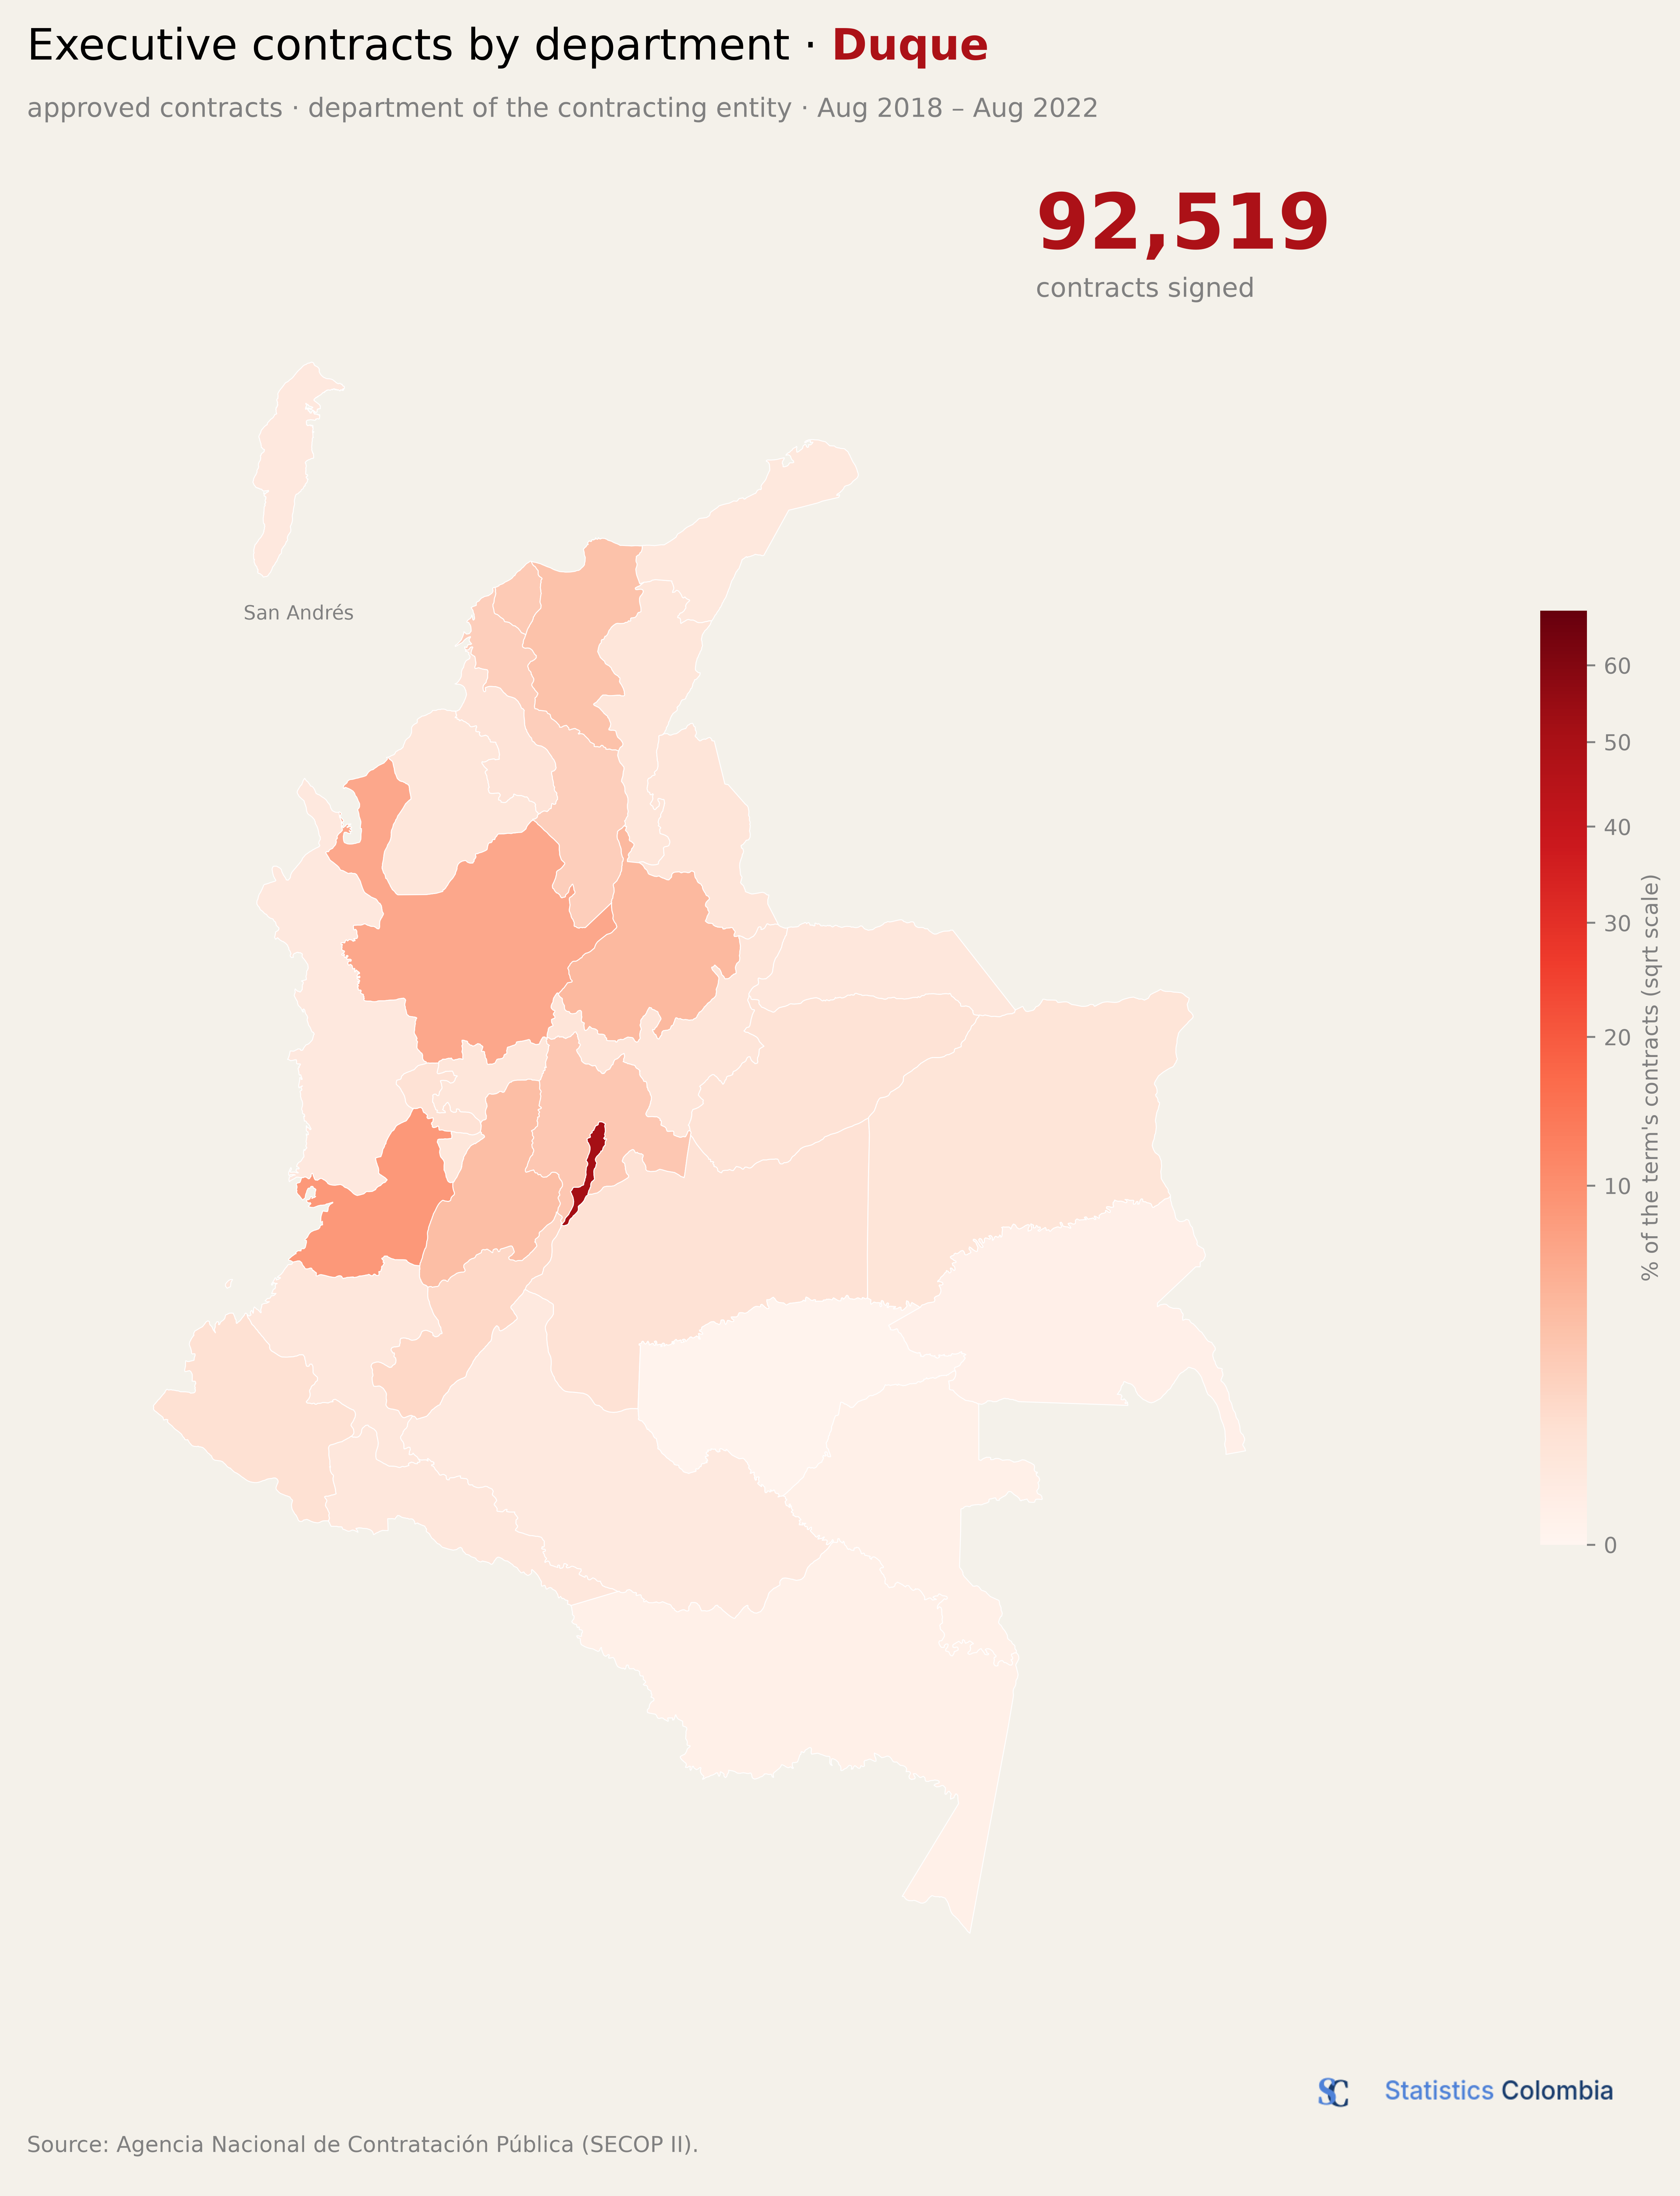

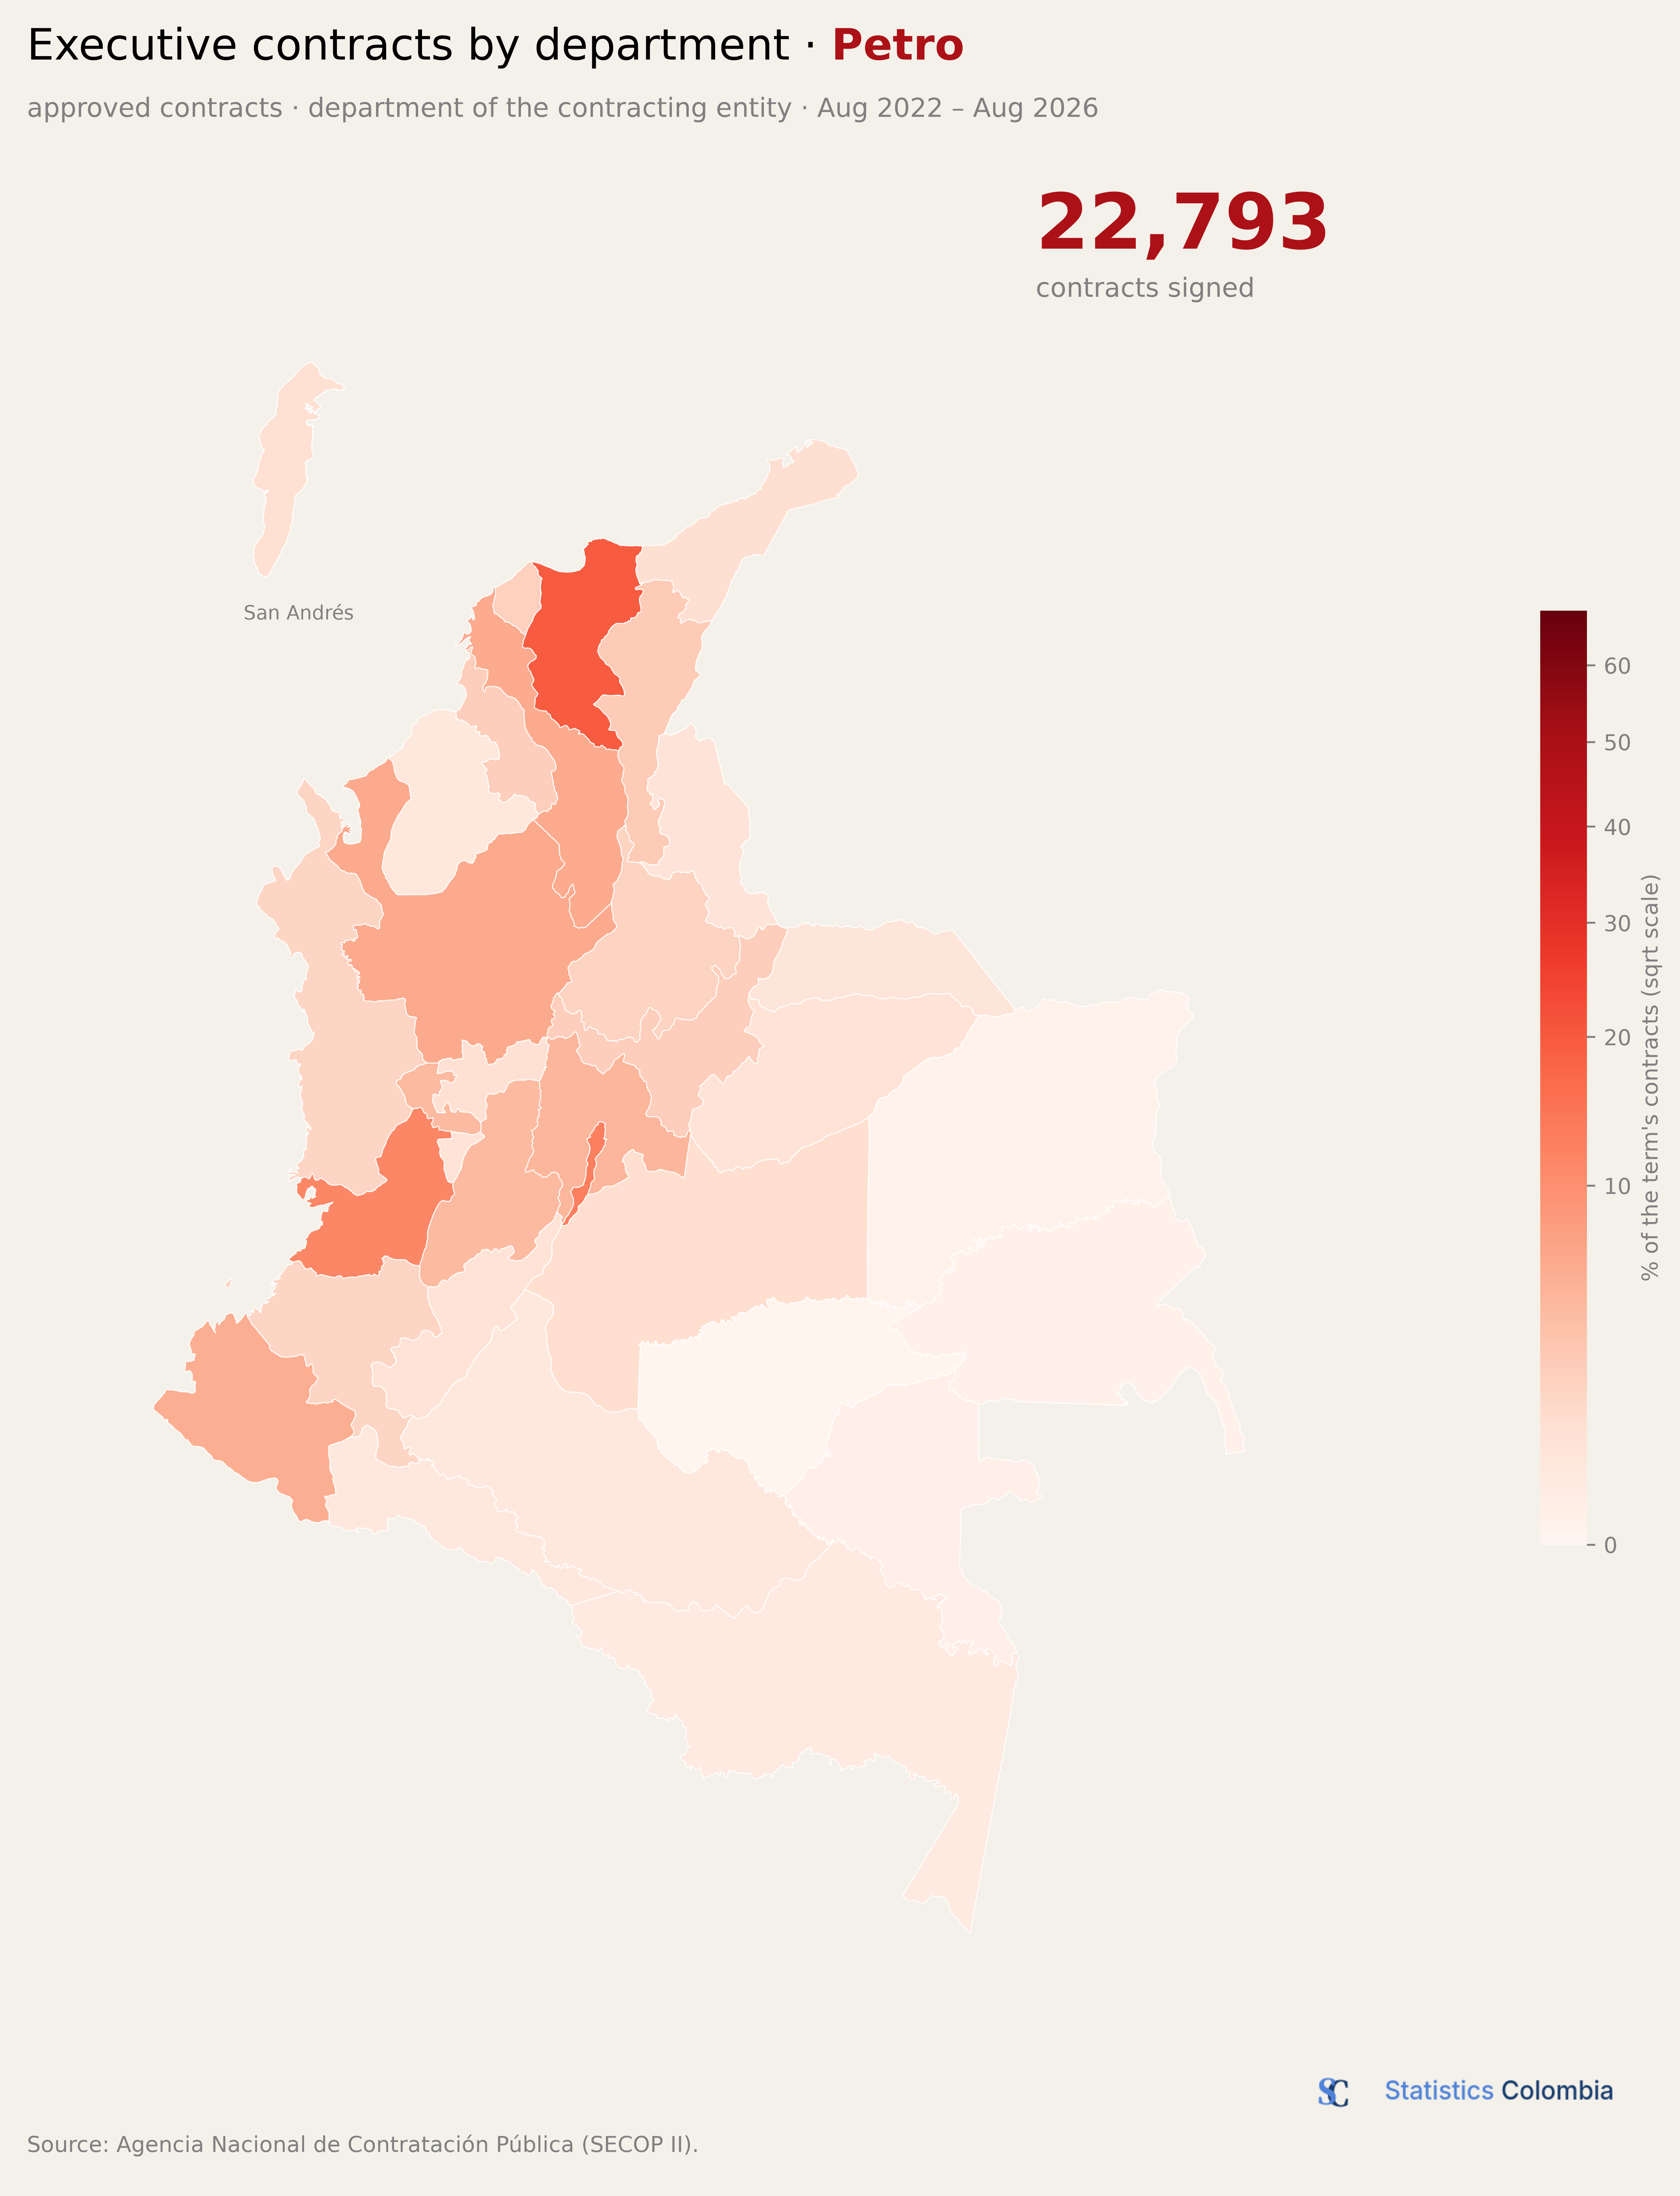

In [18]:
for i, name in enumerate(names):
    start = "Nov 2015" if name == "Santos" else f"Aug {years[i]}"
    plot_term_map(name, f"{start} – Aug {years[i] + 4}")